# Full product catalogue & feature review

Exploratory, as of 30 April 2011, on all 4,894 product codes in the prepared panel. These are candidate features, not verified categories, quality or product origin. No model is trained in this notebook. Run `scripts/build_product_features.py --all`, `scripts/refresh_description_features.py` and `scripts/review_product_features.py --all` first.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
folder = ROOT / 'reports/generated'
data = pd.read_csv(folder / 'product-features-all.csv', dtype={'stock_code': str, 'candidate_code_base': str})
sample = pd.read_csv(folder / 'product-feature-sample-all.csv', dtype={'stock_code': str, 'candidate_code_base': str})
profile = json.loads((folder / 'product-feature-profile-all.json').read_text())
print(f'{len(data)} products, {len(data.columns)} columns; cutoff: {data.as_of.iloc[0]}')

4894 products, 28 columns; cutoff: 2011-04-30


## Random sample for review
A fixed seed of 42 selected 50 products. Compare the original description with the literal tags, candidate pack size and code format. Missing pack size means no recognized pattern, not that a product is sold individually.

In [2]:
display(sample.fillna("—"))

/home/bmage/projects/retailmind-ai-forecasting/.cache/tmp/ipykernel_11408/782230728.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(sample.fillna("—"))


,stock_code,description,code_shape,candidate_code_base,candidate_pack_size,weighted_mean_price_lookback,uk_units_share_lookback,literal_tags
0,17084A,TRANQUILITY MASALA INCENSE,numeric_with_suffix,17084,—,0.21,1.0,—
1,16169N,WRAP BLUE RUSSIAN FOLKART,numeric_with_suffix,16169,—,—,—,blue
2,90084,PINK CRYSTAL GUITAR PHONE CHARM,numeric,—,—,0.85,1.0,pink
3,84706B,FAIRY CAKES TABLE CLOCK,numeric_with_suffix,84706,—,—,—,—
4,90054,CRACKED GLAZE EARRINGS RED,numeric,—,—,—,—,red
5,22802,FAUX FUR CHOCOLATE THROW,numeric,—,—,18.313636,1.0,—
6,21377,SMALL CAMPHOR WOOD FIELD MUSHROOM,numeric,—,—,2.47,1.0,wood
7,90114,SUMMER DAISIES BAG CHARM,numeric,—,—,2.46,1.0,bag
8,20762,GREEN FERN SKETCHBOOK,numeric,—,—,3.75,1.0,—
9,23451,—,numeric,—,—,—,—,—


## Unique values, missingness and coverage
Identifiers and descriptions may have many distinct values; numeric features use quantiles rather than an unreadable list. Binary-tag counts show the exact observed values in this full retrospective code universe.

In [3]:
summary = pd.DataFrame([{'feature': k, 'non_null_unique': v['unique_non_null'], 'missing': v['missing'], 'values_or_quantiles': v.get('value_counts', v.get('quantiles', {}))} for k,v in profile.items()])
display(summary)

,feature,non_null_unique,missing,values_or_quantiles
0,stock_code,4894,0,{}
1,as_of,1,0,{'2011-04-30': 4894}
2,description,4182,528,{}
3,code_shape,3,0,"{'numeric': 3391, 'numeric_with_suffix': 1486,..."
4,candidate_code_base,550,3408,{}
5,candidate_pack_size,17,4492,"{'10.0': 7, '12.0': 35, '15.0': 1, '16.0': 13,..."
6,sales_units_lookback,857,0,"{'0.0': 0.0, '0.25': 0.0, '0.5': 6.0, '0.75': ..."
7,weighted_mean_price_lookback,2210,1945,"{'0.0': 0.001, '0.25': 1.1931088082901553, '0...."
8,invoice_count_lookback,212,0,"{'0.0': 0.0, '0.25': 0.0, '0.5': 2.0, '0.75': ..."
9,uk_units_share_lookback,1130,1945,"{'0.0': 0.0, '0.25': 0.8195488721804511, '0.5'..."


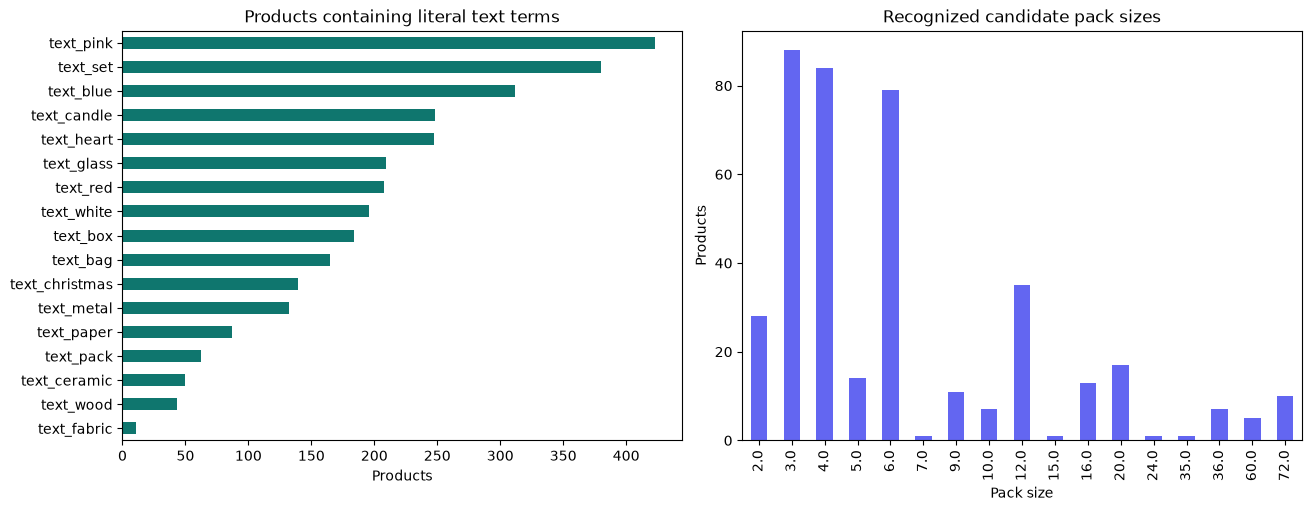

Pack size not recognized: 4492 of 4894


In [4]:
tags=[x for x in data.columns if x.startswith('text_')]
counts=data[tags].sum().sort_values(ascending=True)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
counts.plot.barh(ax=axes[0],color='#0f766e');axes[0].set(title='Products containing literal text terms',xlabel='Products')
data.candidate_pack_size.value_counts().sort_index().plot.bar(ax=axes[1],color='#6366f1');axes[1].set(title='Recognized candidate pack sizes',xlabel='Pack size',ylabel='Products')
plt.show()
print('Pack size not recognized:', int(data.candidate_pack_size.isna().sum()), 'of',len(data))

## Code-family pattern
Some numeric bases with alphabetic suffixes occur on similarly described products, but this is not a documented coding rule. Display every repeated base in the sample for manual checking.

In [5]:
pairs=data[data.candidate_code_base.notna()].groupby('candidate_code_base').filter(lambda g: len(g)>1)
display(pairs[['stock_code','candidate_code_base','description']].sort_values(['candidate_code_base','stock_code']))

,stock_code,candidate_code_base,description
5,10123C,10123,HEARTS WRAPPING TAPE
6,10123G,10123,ARMY CAMO WRAPPING TAPE
7,10124A,10124,SPOTS ON RED BOOKCOVER TAPE
8,10124G,10124,ARMY CAMO BOOKCOVER TAPE
19,15044A,15044,PINK PAPER PARASOL
...,...,...,...
4872,90214U,90214,"LETTER ""U"" BLING KEY RING"
4873,90214V,90214,"LETTER ""V"" BLING KEY RING"
4874,90214W,90214,"LETTER ""W"" BLING KEY RING"
4875,90214Y,90214,"LETTER ""Y"" BLING KEY RING"


## Review observations and limitations
- The 50-row sample includes products without a description at the cutoff; this is missing information, not evidence that a word is absent. Some product codes first appear after the cutoff.
- `SET OF 20 VINTAGE CHRISTMAS NAPKINS` is parsed as 20 and `SEAGRASS S/3 SQU LAUNDRY BOX` as 3. `4 PEAR BOTANICAL DINNER CANDLES` illustrates a leading-number phrase that remains ambiguous and is not extracted.
- Literal tags are not verified categories: “bag” can describe packaging or appear in a name such as “BAG CHARM.” Obvious plurals are recognized, but many synonyms and variants are not.
- Some letter suffixes appear to mark product variants; verify the pattern more broadly before using the candidate code base as a family.
- The list of all 4,894 codes was assembled retrospectively. Although metadata values use only rows available by the cutoff, this list itself is not eligible for a time-safe training cohort.
- Historical prices and customer-country shares are not future values. Neither product quality nor production origin is established.